# Illusion flash-son : analyse des données

**Projet :** réplication en ligne et extension de Shams, Kamitani & Shimojo (2000), *What you see is what you hear*, Nature 408:788 ([doi:10.1038/35048669](https://doi.org/10.1038/35048669)).

**Question.** La vision domine-t-elle vraiment notre perception, ou le son peut-il modifier ce que l'on *voit* ? Et sur quelle fenêtre temporelle le cerveau fusionne-t-il un son et une image ?

**Hypothèses (fixées avant la collecte).**
- **H1 – fission :** un flash unique accompagné de deux bips (1F2B, bips séparés de 57 ms) est plus souvent perçu comme deux flashs qu'un flash sans son (1F0B) ou avec un seul bip (1F1B).
- **H2 – fusion (plus faible) :** deux flashs accompagnés d'un seul bip (2F1B) sont parfois perçus comme un seul flash (comparaison avec 2F0B).
- **H3 – interaction :** dans l'ANOVA à mesures répétées 2 (flashs) × 3 (bips), l'effet du nombre de bips dépend du nombre de flashs.
- **H4 – fenêtre d'intégration (extension) :** l'illusion de fission diminue quand l'écart entre les deux bips augmente (57 → 300 ms) ; la largeur de cette fenêtre varie d'une personne à l'autre et peut être estimée en ajustant une courbe.

**Plan du notebook** (démarche du cours : statistiques descriptives par participant, puis tests inférentiels)
1. Chargement des fichiers CSV (un par participant) ;
2. Critères d'exclusion (fixés à l'avance) ;
3. Statistiques descriptives : moyennes par participant et par condition, graphiques ;
4. Tests : t de Student appariés (H1, H2), ANOVA à mesures répétées (H3), modèle mixte ;
5. Extension : illusion en fonction de l'écart entre les bips, ajustement d'une courbe (H4) ;
6. Analyse de détection du signal (perception ou biais de réponse ?) ;
7. Diagnostics de timing du navigateur ;
8. Conclusion.

In [1]:
from pathlib import Path
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import curve_fit
import pingouin as pg
import statsmodels.formula.api as smf
from statsmodels.stats.anova import AnovaRM

pd.set_option("display.float_format", lambda x: f"{x:.4g}")  # 4 chiffres significatifs (p-valeurs lisibles)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
SIM_DIR = ROOT / "data" / "simulated"
FIG_DIR = ROOT / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chargement des données

Chaque participant produit **un fichier CSV** (une ligne par essai) nommé `flashson_<code>_<date>.csv`. Il suffit de les copier dans `data/raw/`.

> ⚠️ **S'il n'y a encore aucun fichier dans `data/raw/`, le notebook utilise automatiquement les données SIMULÉES de `data/simulated/`** (faux participants générés par `scripts/simulate_participants.py`) afin de vérifier que l'analyse fonctionne. Dans ce cas, tous les titres de figures portent la mention **[SIMULÉ]** et **aucun résultat ne doit être interprété**.

In [2]:
raw_files = sorted(glob.glob(str(RAW_DIR / "*.csv")))
SIMULATED = len(raw_files) == 0
files = sorted(glob.glob(str(SIM_DIR / "*.csv"))) if SIMULATED else raw_files
TAG = " [SIMULÉ]" if SIMULATED else ""
SUFFIX = "_SIMULATED" if SIMULATED else ""

if SIMULATED:
    print("=" * 78)
    print("  ATTENTION : aucune donnée réelle dans data/raw/ -> utilisation des DONNÉES SIMULÉES")
    print("  Ces résultats servent uniquement à tester le notebook. Ne pas les interpréter.")
    print("=" * 78)

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

# Un même code participant avec plusieurs sessions (expérience refaite) : on ne garde que la PREMIÈRE
n_sessions = df.groupby("participant_id").session_id.nunique()
if (n_sessions > 1).any():
    print("Codes avec plusieurs sessions (seule la première est gardée) :", list(n_sessions[n_sessions > 1].index))
    first = df.sort_values("timestamp_iso").groupby("participant_id").session_id.first()
    df = df[df.session_id.isin(first.values)]
print(f"{len(files)} fichiers, {df.participant_id.nunique()} participants, {len(df)} lignes")
df.head()

  ATTENTION : aucune donnée réelle dans data/raw/ -> utilisation des DONNÉES SIMULÉES
  Ces résultats servent uniquement à tester le notebook. Ne pas les interpréter.
15 fichiers, 15 participants, 1650 lignes


,participant_id,session_id,experiment_version,timestamp_iso,block,trial_in_block,trial_global,condition,n_flashes,n_beeps,...,audio_device,vision,hearing,audio_check_score,user_agent,screen_w,screen_h,device_pixel_ratio,random_seed,aborted
0,SIM01,SIMULATED-01,1.0.0-SIMULATED,2026-12-01T13:00:02.400000Z,audiocheck,1,1,0F1B,0,1,...,external_speakers,corrected,normal,6/6,SIMULATED,1920,1080,1,1111671333,0
1,SIM01,SIMULATED-01,1.0.0-SIMULATED,2026-12-01T13:00:04.800000Z,audiocheck,2,2,0F2B,0,2,...,external_speakers,corrected,normal,6/6,SIMULATED,1920,1080,1,1766566614,0
2,SIM01,SIMULATED-01,1.0.0-SIMULATED,2026-12-01T13:00:07.200000Z,audiocheck,3,3,0F2B,0,2,...,external_speakers,corrected,normal,6/6,SIMULATED,1920,1080,1,1153355214,0
3,SIM01,SIMULATED-01,1.0.0-SIMULATED,2026-12-01T13:00:09.600000Z,audiocheck,4,4,0F1B,0,1,...,external_speakers,corrected,normal,6/6,SIMULATED,1920,1080,1,579238995,0
4,SIM01,SIMULATED-01,1.0.0-SIMULATED,2026-12-01T13:00:12Z,audiocheck,5,5,0F2B,0,2,...,external_speakers,corrected,normal,6/6,SIMULATED,1920,1080,1,1314278591,0


### Description des sessions

Une ligne par session : informations déclarées par le participant et mesures automatiques du navigateur (fréquence de l'écran, latence audio annoncée, etc.).

In [3]:
def last_score(s):
    # "5/6" ou "4/6;6/6" (test d'écoute refait) -> proportion correcte à la dernière tentative
    try:
        a, b = str(s).split(";")[-1].split("/")
        return int(a) / int(b)
    except Exception:
        return np.nan

sessions = (df.groupby("participant_id")
              .agg(age=("age", "first"), genre=("gender", "first"), lateralite=("handedness", "first"),
                   audio=("audio_device", "first"), test_ecoute=("audio_check_score", "first"),
                   refresh_hz=("refresh_hz", "median"), latence_sortie_ms=("output_latency_ms", "median"),
                   n_essais_main=("block", lambda b: (b == "main").sum()), interrompu=("aborted", "max")))
sessions["test_ecoute_prop"] = sessions.test_ecoute.map(last_score)
sessions

,age,genre,lateralite,audio,test_ecoute,refresh_hz,latence_sortie_ms,n_essais_main,interrompu,test_ecoute_prop
participant_id,,,,,,,,,,
SIM01,24,M,right,external_speakers,6/6,144,24.1,98,0,1
SIM02,20,F,right,external_speakers,6/6,60,21.65,98,0,1
SIM03,20,M,right,wired_headphones,6/6,60,24.05,98,0,1
SIM04,21,F,right,external_speakers,6/6,60,27,98,0,1
SIM05,23,M,right,external_speakers,6/6,60,24.05,98,0,1
SIM06,26,F,right,wired_headphones,5/6,144,25.75,98,0,0.8333
SIM07,25,F,right,laptop_speakers,6/6,144,24.65,98,0,1
SIM08,22,undisclosed,right,external_speakers,6/6,60,23.25,98,0,1
SIM09,23,M,right,wired_headphones,6/6,60,22.7,98,0,1


## 2. Critères d'exclusion

Les critères sont fixés **avant** de regarder les résultats (ils sont aussi décrits dans le README).

**Au niveau de l'essai** (essais principaux uniquement), un essai est exclu si :
- au moins une image a été perdue pendant le stimulus (`n_dropped_frames > 0`) ;
- le flash est apparu plus d'une demi-image en retard sur l'instant prévu (`|flash_late_ms| > frame_ms / 2`), ce qui décale le son par rapport à l'image ;
- le son a été programmé trop tard (`audio_scheduled_late == 1`) ;
- l'onglet a été masqué pendant l'essai (`tab_hidden == 1`) ;
- le temps de réponse est < 100 ms (réponse anticipée) ou > 10 s (inattention).

**Au niveau du participant**, une session est exclue si :
- elle a été faite avec des **écouteurs Bluetooth** (retard du son de 100 à 300 ms) ;
- le **test d'écoute** (1 ou 2 bips ?) est réussi à moins de 5/6 (le participant n'entend pas bien les bips) ;
- les **essais de contrôle** sont ratés : moins de 75 % de « 2 » pour les essais faciles à 2 flashs séparés de 150 ms, ou moins de 70 % de « 1 » pour un flash sans son ;
- l'écran est rafraîchi à moins de 50 Hz ;
- plus de 20 % des essais principaux sont exclus pour des raisons de timing ;
- moins de 80 % des essais principaux ont été réalisés.

In [4]:
main = df[df.block == "main"].copy()
main["two"] = (main.response == 2).astype(int)        # a répondu « 2 flashs »

half_frame = main.frame_ms / 2
main["bad_timing"] = ((main.n_dropped_frames.fillna(0) > 0)
                      | (main.flash_late_ms.abs() > half_frame).fillna(False)
                      | (main.audio_scheduled_late.fillna(0) == 1)
                      | (main.tab_hidden.fillna(0) == 1))
main["bad_rt"] = (main.rt_ms < 100) | (main.rt_ms > 10000)
main["exclude_trial"] = main.bad_timing | main.bad_rt

n_expected = (pd.read_csv(ROOT / "experiment" / "trials.csv").block == "main").sum()
q = main.groupby("participant_id").agg(
    catch_ok=("two", lambda s: np.nan),  # rempli ci-dessous
    pct_bad_timing=("bad_timing", "mean"),
    n_main=("two", "size"))
q["catch_ok"] = main[main.condition == "2F0B_catch"].groupby("participant_id").two.mean()
q["one_flash_ok"] = 1 - main[main.condition == "1F0B"].groupby("participant_id").two.mean()
q = q.join(sessions[["audio", "test_ecoute_prop", "refresh_hz"]])

reasons = pd.DataFrame(index=q.index)
reasons["bluetooth"] = q.audio == "bluetooth"
reasons["test_ecoute<5/6"] = q.test_ecoute_prop < 5 / 6 - 1e-9
reasons["controle_2flashs<75%"] = q.catch_ok < 0.75
reasons["controle_1flash<70%"] = q.one_flash_ok < 0.70
reasons["ecran<50Hz"] = q.refresh_hz < 50
reasons["timing>20%"] = q.pct_bad_timing > 0.20
reasons["incomplet"] = q.n_main < 0.8 * n_expected
q["exclu"] = reasons.any(axis=1)
q["raisons"] = reasons.apply(lambda r: ", ".join(r.index[r]), axis=1)
display(q.round(3))

kept = q.index[~q.exclu]
print(f"Participants exclus : {int(q.exclu.sum())} / {len(q)}  ->  {len(kept)} participants analysés")
d = main[main.participant_id.isin(kept) & ~main.exclude_trial].copy()
print(f"Essais exclus chez les participants gardés : "
      f"{main[main.participant_id.isin(kept)].exclude_trial.mean():.1%}")

,catch_ok,pct_bad_timing,n_main,one_flash_ok,audio,test_ecoute_prop,refresh_hz,exclu,raisons
participant_id,,,,,,,,,
SIM01,1,0.041,98,1,external_speakers,1,144,False,
SIM02,1,0.041,98,0.8,external_speakers,1,60,False,
SIM03,1,0.01,98,0.9,wired_headphones,1,60,False,
SIM04,1,0.031,98,1,external_speakers,1,60,False,
SIM05,1,0.041,98,1,external_speakers,1,60,False,
SIM06,0.75,0.02,98,1,wired_headphones,0.833,144,False,
SIM07,1,0.031,98,0.9,laptop_speakers,1,144,False,
SIM08,1,0.02,98,1,external_speakers,1,60,False,
SIM09,1,0,98,0.9,wired_headphones,1,60,False,


Participants exclus : 2 / 15  ->  13 participants analysés
Essais exclus chez les participants gardés : 2.7%


## 3. Statistiques descriptives

### 3.1 Nombre moyen de flashs perçus, par participant et par condition

On se limite d'abord au cœur du plan (écart de 57 ms entre les bips, comme dans l'article) : 2 nombres de flashs × 3 nombres de bips. Pour chaque participant, on calcule le **nombre moyen de flashs rapportés** dans chacune des 6 conditions (c'est la mesure de la figure 1 de Shams et al.).

In [5]:
core = d[d.part == "core"].copy()
per_subj = (core.groupby(["participant_id", "n_flashes", "n_beeps"])
                .response.mean().rename("mean_flashes").reset_index())
table = per_subj.pivot_table(index="participant_id", columns=["n_flashes", "n_beeps"], values="mean_flashes")
table.columns = [f"{f}F{b}B" for f, b in table.columns]
display(table.round(2))
print("Moyenne du groupe (± écart-type) :")
display(table.agg(["mean", "std"]).round(2))

,1F0B,1F1B,1F2B,2F0B,2F1B,2F2B
participant_id,,,,,,
SIM01,1,1.11,1.42,1.7,1.67,1.9
SIM02,1.22,1,1.45,1.6,1.6,2
SIM03,1.1,1.2,1.83,2,1.8,2
SIM04,1,1.1,1.45,1.8,1.6,2
SIM05,1,1.2,1.83,2,1.6,2
SIM06,1,1,1.36,2,1.6,1.9
SIM07,1.1,1.2,1.64,1.7,1.4,2
SIM08,1,1,1.42,2,1.44,1.9
SIM09,1.1,1.1,1.42,2,1.8,2


Moyenne du groupe (± écart-type) :


,1F0B,1F1B,1F2B,2F0B,2F1B,2F2B
mean,1.06,1.09,1.59,1.82,1.56,1.97
std,0.07,0.09,0.19,0.16,0.15,0.05


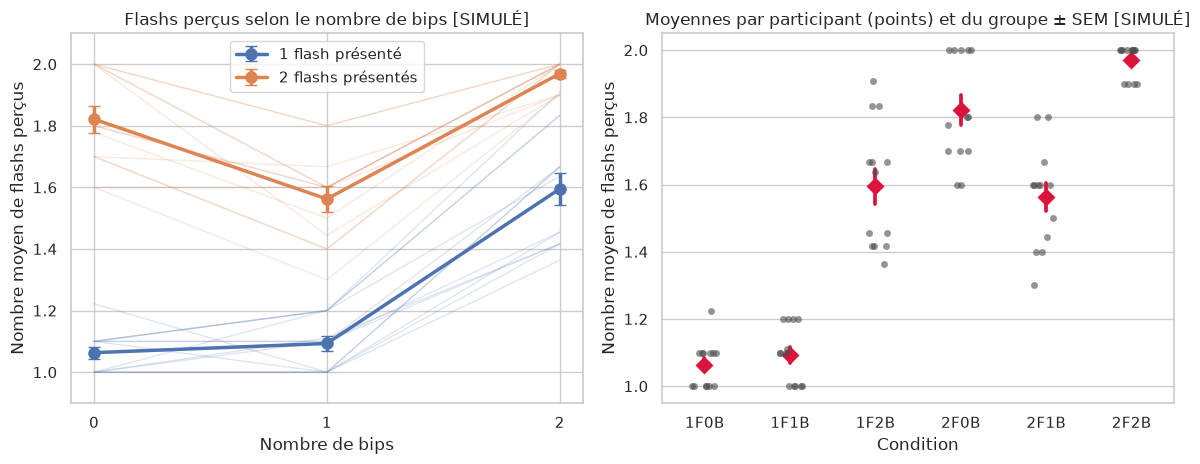

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
for (pid, nf), g in per_subj.groupby(["participant_id", "n_flashes"]):
    ax.plot(g.n_beeps, g.mean_flashes, color="C0" if nf == 1 else "C1", alpha=0.18, lw=1)
grp = per_subj.groupby(["n_flashes", "n_beeps"]).mean_flashes.agg(["mean", "sem"]).reset_index()
for nf, g in grp.groupby("n_flashes"):
    ax.errorbar(g.n_beeps, g["mean"], yerr=g["sem"], marker="o", ms=8, lw=2.5, capsize=4,
                color="C0" if nf == 1 else "C1", label=f"{nf} flash{'s' if nf > 1 else ''} présenté{'s' if nf > 1 else ''}")
ax.set_xticks([0, 1, 2]); ax.set_ylim(0.9, 2.1)
ax.set_xlabel("Nombre de bips"); ax.set_ylabel("Nombre moyen de flashs perçus")
ax.set_title("Flashs perçus selon le nombre de bips" + TAG)
ax.legend()

ax = axes[1]
sns.stripplot(data=per_subj.assign(cond=per_subj.n_flashes.astype(str) + "F" + per_subj.n_beeps.astype(str) + "B"),
              x="cond", y="mean_flashes", order=["1F0B", "1F1B", "1F2B", "2F0B", "2F1B", "2F2B"],
              color="0.3", alpha=0.6, jitter=0.15, ax=ax)
sns.pointplot(data=per_subj.assign(cond=per_subj.n_flashes.astype(str) + "F" + per_subj.n_beeps.astype(str) + "B"),
              x="cond", y="mean_flashes", order=["1F0B", "1F1B", "1F2B", "2F0B", "2F1B", "2F2B"],
              color="crimson", errorbar="se", linestyle="none", markers="D", ax=ax)
ax.set_xlabel("Condition"); ax.set_ylabel("Nombre moyen de flashs perçus")
ax.set_title("Moyennes par participant (points) et du groupe ± SEM" + TAG)
plt.tight_layout()
plt.savefig(FIG_DIR / f"fig1_flashs_percus{SUFFIX}.png", dpi=150)
plt.show()

**Lecture.** Sans illusion, les deux courbes seraient plates (1 et 2 flashs quel que soit le son). L'illusion de **fission** se voit si la courbe « 1 flash » monte avec 2 bips ; l'illusion de **fusion** si la courbe « 2 flashs » descend avec 1 bip.

## 4. Tests inférentiels

### 4.1 H1 – Illusion de fission : 1F2B vs 1F0B (t de Student apparié)

Chaque participant fournit une moyenne dans chaque condition ; on compare ces moyennes **appariées** (même personne dans les deux conditions). On rapporte aussi la taille d'effet (d de Cohen), l'intervalle de confiance à 95 % et, par robustesse, un test non paramétrique de Wilcoxon.

In [7]:
def paired(a, b, label):
    x, y = table[a], table[b]
    res = pg.ttest(x, y, paired=True)
    w = pg.wilcoxon(x, y)
    print(f"{label} : {a} = {x.mean():.2f} ± {x.std():.2f}  vs  {b} = {y.mean():.2f} ± {y.std():.2f}  (n = {len(x)})")
    r = res.iloc[0]
    pcol = "p_val" if "p_val" in res.columns else "p-val"
    ci = r["CI95"] if "CI95" in res.columns else r["CI95%"]
    print(f"   t({int(r['dof'])}) = {r['T']:.2f}, p = {r[pcol]:.3g}, d de Cohen = {r['cohen_d']:.2f}, "
          f"IC95 de la différence = [{ci[0]:.2f}, {ci[1]:.2f}], BF10 = {r['BF10']}")
    print(f"   Wilcoxon : W = {w['W_val'].iloc[0] if 'W_val' in w else w.iloc[0, 0]:.1f}, "
          f"p = {w['p_val'].iloc[0] if 'p_val' in w else w.iloc[0, 2]:.4g}")
    return res

h1 = paired("1F2B", "1F0B", "H1 fission")
h1b = paired("1F2B", "1F1B", "Contrôle : 2 bips vs 1 bip (l'effet ne vient pas de la simple présence d'un son)")

H1 fission : 1F2B = 1.59 ± 0.19  vs  1F0B = 1.06 ± 0.07  (n = 13)
   t(12) = 10.18, p = 2.96e-07, d de Cohen = 3.78, IC95 de la différence = [0.42, 0.65], BF10 = 5.064e+04
   Wilcoxon : W = 0.0, p = 0.0002441
Contrôle : 2 bips vs 1 bip (l'effet ne vient pas de la simple présence d'un son) : 1F2B = 1.59 ± 0.19  vs  1F1B = 1.09 ± 0.09  (n = 13)
   t(12) = 12.21, p = 3.98e-08, d de Cohen = 3.45, IC95 de la différence = [0.41, 0.59], BF10 = 3.091e+05
   Wilcoxon : W = 0.0, p = 0.0002441


### 4.2 H2 – Illusion de fusion : 2F1B vs 2F0B

In [8]:
h2 = paired("2F1B", "2F0B", "H2 fusion")

H2 fusion : 2F1B = 1.56 ± 0.15  vs  2F0B = 1.82 ± 0.16  (n = 13)
   t(12) = -6.28, p = 4.05e-05, d de Cohen = 1.67, IC95 de la différence = [-0.35, -0.17], BF10 = 635.9
   Wilcoxon : W = 0.0, p = 0.0004883


### 4.3 H3 – ANOVA à mesures répétées 2 (flashs) × 3 (bips)

Variable dépendante : nombre moyen de flashs perçus par participant et par condition. Le facteur « bips » a 3 niveaux : on vérifie la sphéricité et on applique si besoin la correction de Greenhouse-Geisser (`p-GG-corr`). La même ANOVA est recalculée avec `statsmodels` (`AnovaRM`) pour vérification.

In [9]:
aov = pg.rm_anova(data=per_subj, dv="mean_flashes", within=["n_flashes", "n_beeps"],
                  subject="participant_id", detailed=True)
display(aov)
print(AnovaRM(per_subj, depvar="mean_flashes", subject="participant_id",
              within=["n_flashes", "n_beeps"]).fit())

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps,sphericity,W_spher,p_spher
0,n_flashes,5.558,1,12,5.558,185.3,1.173e-08,1.173e-08,0.8264,1,True,NaN,1
1,n_beeps,2.903,2,24,1.452,115.2,4.962e-13,8.638e-11,0.7133,0.7965,True,0.7446,0.1975
2,n_flashes * n_beeps,0.5197,2,24,0.2598,24.21,1.753e-06,1.995e-05,0.3081,0.7696,True,0.7006,0.1413


                     Anova
                  F Value  Num DF  Den DF Pr > F
------------------------------------------------
n_flashes         185.2914 1.0000 12.0000 0.0000
n_beeps           115.2159 2.0000 24.0000 0.0000
n_flashes:n_beeps  24.2127 2.0000 24.0000 0.0000



**Comparaisons post-hoc** (t appariés, correction de Holm) : effet du nombre de bips séparément pour 1 flash et pour 2 flashs.

In [10]:
post = pg.pairwise_tests(data=per_subj, dv="mean_flashes", within=["n_flashes", "n_beeps"],
                         subject="participant_id", padjust="holm")
cols = [c for c in ["Contrast", "n_flashes", "A", "B", "T", "dof", "p_unc", "p_corr", "p-unc", "p-corr", "hedges"] if c in post.columns]
display(post[post.Contrast == "n_flashes * n_beeps"][cols])

,Contrast,n_flashes,A,B,T,dof,p_unc,p_corr,hedges
4,n_flashes * n_beeps,1,0,1,-0.9982,12,0.3379,0.3379,-0.3703
5,n_flashes * n_beeps,1,0,2,-10.18,12,2.959e-07,1.479e-06,-3.66
6,n_flashes * n_beeps,1,1,2,-12.21,12,3.981e-08,2.389e-07,-3.343
7,n_flashes * n_beeps,2,0,1,6.283,12,4.049e-05,0.0001215,1.621
8,n_flashes * n_beeps,2,0,2,-3.19,12,0.007775,0.01555,-1.217
9,n_flashes * n_beeps,2,1,2,-10.16,12,3.024e-07,1.479e-06,-3.536


### 4.4 Pour aller plus loin : modèle linéaire mixte (essai par essai)

Plutôt que de moyenner, on peut modéliser **chaque essai** avec un effet aléatoire par participant (approche « mixed model » évoquée en cours). Ici, un modèle linéaire mixte sur la réponse (1 ou 2) ; un modèle logistique mixte (`glmer` en R / `lme4`) serait l'analyse idéale pour une réponse binaire. (Avec les données simulées, la variance entre participants est quasi nulle, d'où un éventuel avertissement de convergence « boundary » sans gravité.)

In [11]:
core["flashes"] = core.n_flashes.astype(str) + "F"
core["beeps"] = core.n_beeps.astype(str) + "B"
mm = smf.mixedlm("response ~ C(flashes) * C(beeps)", data=core, groups=core.participant_id).fit(reml=True)
print(mm.summary())

                  Mixed Linear Model Regression Results
Model:                   MixedLM       Dependent Variable:       response 
No. Observations:        786           Method:                   REML     
No. Groups:              13            Scale:                    0.1384   
Min. group size:         59            Log-Likelihood:           -352.9040
Max. group size:         62            Converged:                Yes      
Mean group size:         60.5                                             
--------------------------------------------------------------------------
                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------
Intercept                        1.063    0.035 30.598 0.000  0.995  1.132
C(flashes)[T.2F]                 0.757    0.047 16.219 0.000  0.666  0.849
C(beeps)[T.1B]                   0.031    0.047  0.657 0.511 -0.061  0.122
C(beeps)[T.2B]                   0.532    0.

/tmp/ipykernel_149811/3597319248.py:3: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  mm = smf.mixedlm("response ~ C(flashes) * C(beeps)", data=core, groups=core.participant_id).fit(reml=True)


## 5. Extension – fenêtre d'intégration temporelle (H4)

Dans la condition 1 flash + 2 bips, l'écart entre les deux bips varie : 57 (cœur du plan), 100, 150, 200 et 300 ms. Pour chaque participant, on calcule la **proportion de réponses « 2 flashs »** à chaque écart, qu'on compare au taux de « 2 » sans son (1F0B, ligne de base).

In [12]:
fis = d[(d.n_flashes == 1) & (d.n_beeps == 2)].copy()
soa_subj = fis.groupby(["participant_id", "beep_soa_ms"]).two.mean().rename("p_two").reset_index()
base_subj = d[d.condition == "1F0B"].groupby("participant_id").two.mean().rename("base")
soa_tab = soa_subj.pivot(index="participant_id", columns="beep_soa_ms", values="p_two")
display(soa_tab.join(base_subj).round(2))

aov_soa = pg.rm_anova(data=soa_subj, dv="p_two", within="beep_soa_ms", subject="participant_id", detailed=True)
print("ANOVA à mesures répétées, effet de l'écart entre les bips :")
display(aov_soa)

,57,100,150,200,300,base
participant_id,,,,,,
SIM01,0.42,0.25,0.12,0,0,0
SIM02,0.45,0.62,0.29,0.38,0.12,0.22
SIM03,0.83,0.62,0.75,0.62,0.43,0.1
SIM04,0.45,0.5,0.5,0.29,0.5,0
SIM05,0.83,0.62,0.5,0.33,0.38,0
SIM06,0.36,0.38,0.14,0.12,0,0
SIM07,0.64,0.43,0.38,0.25,0,0.1
SIM08,0.42,0.38,0,0.12,0.14,0
SIM09,0.42,0,0.12,0.25,0,0.1


ANOVA à mesures répétées, effet de l'écart entre les bips :


,Source,SS,DF,MS,F,p_unc,ng2,eps
0,beep_soa_ms,1.646,4,0.4115,22.77,1.364e-10,0.4302,0.8098
1,Error,0.8675,48,0.01807,NaN,NaN,NaN,NaN


### Ajustement d'une courbe

On ajuste, pour chaque participant, une **demi-gaussienne** (comme Flanagan et al., 2025, pour les essais où le son suit le flash) :

$$P(\text{« 2 »} \mid \text{SOA}) = b + A \cdot \exp\left(-\frac{\text{SOA}^2}{2\sigma^2}\right)$$

- $b$ : ligne de base, fixée au taux de « 2 » du participant pour 1 flash sans son ;
- $A$ : amplitude (force maximale de l'illusion) ;
- $\sigma$ : largeur ; la **fenêtre d'intégration** est définie comme l'écart pour lequel l'illusion tombe à la moitié de son maximum : $\text{TBW}_{50} = \sigma\sqrt{2\ln 2} \approx 1{,}18\,\sigma$.

Comme dans l'article de 2025, on ne garde que les ajustements individuels de bonne qualité ($R^2 \geq 0{,}6$). Avec 8 à 12 essais par point, les estimations individuelles restent bruitées : elles sont surtout illustratives ; l'ajustement sur les moyennes du groupe est plus fiable.

In [13]:
def half_gauss(soa, A, sigma, b):
    return b + A * np.exp(-np.asarray(soa, float) ** 2 / (2 * sigma ** 2))

def fit_subject(x, y, b):
    f = lambda s, A, sigma: half_gauss(s, A, sigma, b)
    try:
        (A, sigma), _ = curve_fit(f, x, y, p0=[max(0.05, y.max() - b), 120], bounds=([0, 20], [1, 1000]))
    except RuntimeError:
        return np.nan, np.nan, np.nan
    pred = f(x, A, sigma)
    ss_res, ss_tot = ((y - pred) ** 2).sum(), ((y - y.mean()) ** 2).sum()
    return A, sigma, 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

soas = soa_tab.columns.values.astype(float)
fits = []
for pid, row in soa_tab.iterrows():
    A, sigma, r2 = fit_subject(soas, row.values, base_subj[pid])
    fits.append(dict(participant_id=pid, base=base_subj[pid], A=A, sigma=sigma, R2=r2,
                     TBW50_ms=sigma * np.sqrt(2 * np.log(2)), illusion57=row[57]))
fits = pd.DataFrame(fits).set_index("participant_id")
fits["bon_ajustement"] = fits.R2 >= 0.6
display(fits.round(3))
good = fits[fits.bon_ajustement]
print(f"Ajustements retenus : {len(good)}/{len(fits)} ; "
      f"TBW50 médiane = {good.TBW50_ms.median():.0f} ms (IQR {good.TBW50_ms.quantile(.25):.0f}–{good.TBW50_ms.quantile(.75):.0f} ms)")

# ajustement sur la moyenne du groupe
mean_curve = soa_tab.mean()
gA, gsig, gR2 = fit_subject(soas, mean_curve.values, base_subj.mean())
print(f"Groupe : A = {gA:.2f}, sigma = {gsig:.0f} ms, TBW50 = {gsig * np.sqrt(2 * np.log(2)):.0f} ms, R² = {gR2:.2f}")

,base,A,sigma,R2,TBW50_ms,illusion57,bon_ajustement
participant_id,,,,,,,
SIM01,0,0.526,83.3,0.989,98.08,0.417,True
SIM02,0.222,0.352,120.6,0.591,142,0.455,False
SIM03,0.1,0.697,253.2,0.766,298.1,0.833,True
SIM04,0,0.455,1000,-0.005,1177,0.455,False
SIM05,0,0.751,198.2,0.693,233.4,0.833,True
SIM06,0,0.444,117,0.916,137.8,0.364,True
SIM07,0.1,0.583,111.6,0.908,131.4,0.636,True
SIM08,0,0.548,88.04,0.588,103.7,0.417,False
SIM09,0.1,1,36.15,0.614,42.56,0.417,True


Ajustements retenus : 9/13 ; TBW50 médiane = 129 ms (IQR 102–138 ms)
Groupe : A = 0.56, sigma = 125 ms, TBW50 = 147 ms, R² = 0.96


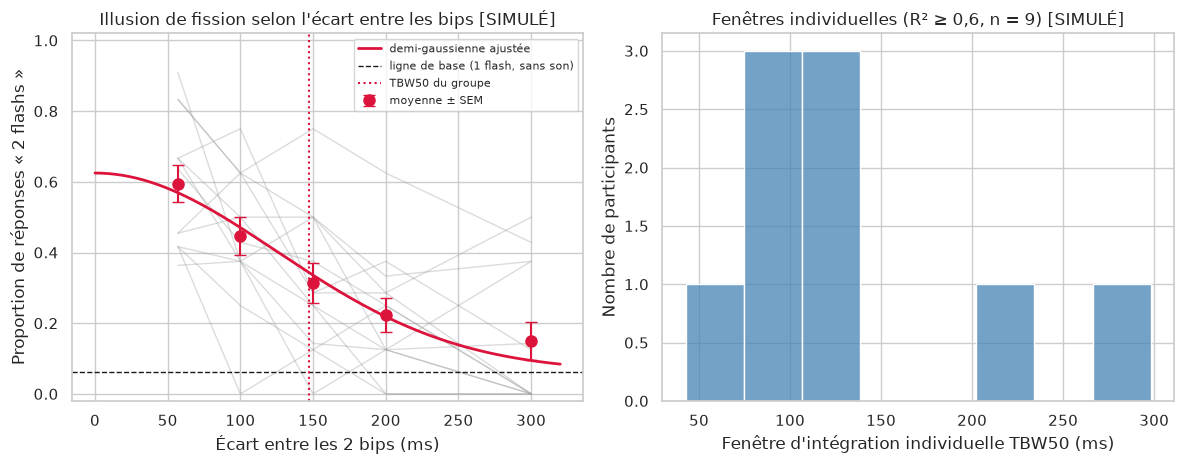

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
xs = np.linspace(0, 320, 200)
for pid, row in soa_tab.iterrows():
    ax.plot(soas, row.values, "-", color="0.6", alpha=0.35, lw=1)
ax.errorbar(soas, mean_curve, yerr=soa_tab.sem(), fmt="o", color="crimson", ms=8, capsize=4, label="moyenne ± SEM")
ax.plot(xs, half_gauss(xs, gA, gsig, base_subj.mean()), color="crimson", lw=2, label="demi-gaussienne ajustée")
ax.axhline(base_subj.mean(), ls="--", color="k", lw=1, label="ligne de base (1 flash, sans son)")
ax.axvline(gsig * np.sqrt(2 * np.log(2)), ls=":", color="crimson", lw=1.5, label="TBW50 du groupe")
ax.set_xlabel("Écart entre les 2 bips (ms)"); ax.set_ylabel("Proportion de réponses « 2 flashs »")
ax.set_ylim(-0.02, 1.02); ax.set_title("Illusion de fission selon l'écart entre les bips" + TAG); ax.legend(fontsize=8)

ax = axes[1]
if len(good) > 0:
    sns.histplot(good.TBW50_ms, bins=8, ax=ax, color="steelblue")
ax.set_xlabel("Fenêtre d'intégration individuelle TBW50 (ms)"); ax.set_ylabel("Nombre de participants")
ax.set_title(f"Fenêtres individuelles (R² ≥ 0,6, n = {len(good)})" + TAG)
plt.tight_layout()
plt.savefig(FIG_DIR / f"fig2_fenetre_integration{SUFFIX}.png", dpi=150)
plt.show()

**Question complémentaire.** Les personnes qui ont une fenêtre d'intégration plus large sont-elles plus sensibles à l'illusion à 57 ms ? (Stevenson, Zemtsov & Wallace, 2012, ont rapporté un tel lien.) Corrélation de Spearman, sur les ajustements retenus.

In [15]:
if len(good) >= 4:
    display(pg.corr(good.TBW50_ms, good.illusion57, method="spearman"))
else:
    print("Pas assez d'ajustements retenus pour une corrélation.")

,n,r,CI95,p_val,power
spearman,9,0.3545,"[-0.41, 0.82]",0.3493,0.1584


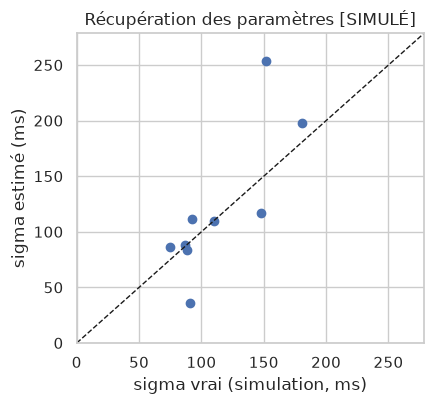

Corrélation vrai/estimé : 0.79


In [16]:
# Vérification de la chaîne d'analyse : uniquement avec les données simulées,
# on compare la largeur estimée à la vraie valeur utilisée pour la simulation.
if SIMULATED and (SIM_DIR / "ground_truth_SIMULATED.txt").exists():
    truth = pd.read_csv(SIM_DIR / "ground_truth_SIMULATED.txt", sep="\t", comment="#").set_index("participant_id")
    cmp = good.join(truth[["sigma_ms"]])
    plt.figure(figsize=(4.5, 4.2))
    plt.scatter(cmp.sigma_ms, cmp.sigma)
    lim = [0, max(cmp.sigma_ms.max(), cmp.sigma.max()) * 1.1]
    plt.plot(lim, lim, "k--", lw=1); plt.xlim(lim); plt.ylim(lim)
    plt.xlabel("sigma vrai (simulation, ms)"); plt.ylabel("sigma estimé (ms)")
    plt.title("Récupération des paramètres [SIMULÉ]")
    plt.tight_layout(); plt.show()
    print("Corrélation vrai/estimé :", round(np.corrcoef(cmp.sigma_ms, cmp.sigma)[0, 1], 2))

## 6. Perception ou biais de réponse ? (théorie de la détection du signal)

Répondre « 2 » avec deux bips pourrait refléter un **biais de décision** (« j'ai entendu 2, je dis 2 ») plutôt qu'un vrai changement de perception. Comme Flanagan et al. (2025), on calcule pour chaque participant la **sensibilité d′** à la différence 1 vs 2 flashs :
- **avec deux bips** : « signal » = 2F2B (réponse « 2 » = détection), « bruit » = 1F2B (réponse « 2 » = fausse alarme) ;
- **sans son** : signal = 2F0B, bruit = 1F0B.

Si les bips rendent les flashs *perceptivement* indiscernables, d′ doit baisser avec les bips. Le critère c mesure le biais (c < 0 : tendance à répondre « 2 »). Correction des taux extrêmes : 0 → 0,5/N, 1 → (N − 0,5)/N.

In [17]:
def rate(x):
    n, k = len(x), x.sum()
    p = k / n
    return min(max(p, 0.5 / n), (n - 0.5) / n)

rows = []
for pid, g in core.groupby("participant_id"):
    out = {"participant_id": pid}
    for lab, sig, noise in [("son", "2F2B", "1F2B"), ("sans_son", "2F0B", "1F0B")]:
        H, F = rate(g[g.condition == sig].two), rate(g[g.condition == noise].two)
        out[f"dprime_{lab}"] = stats.norm.ppf(H) - stats.norm.ppf(F)
        out[f"c_{lab}"] = -0.5 * (stats.norm.ppf(H) + stats.norm.ppf(F))
    rows.append(out)
sdt = pd.DataFrame(rows).set_index("participant_id")
display(sdt.agg(["mean", "std"]).round(2))
print("d\u2032 avec 2 bips vs sans son :"); display(pg.ttest(sdt.dprime_son, sdt.dprime_sans_son, paired=True))
print("Critère c avec 2 bips vs sans son :"); display(pg.ttest(sdt.c_son, sdt.c_sans_son, paired=True))

,dprime_son,c_son,dprime_sans_son,c_sans_son
mean,1.23,-0.9,2.37,0.21
std,0.54,0.3,0.73,0.25


d′ avec 2 bips vs sans son :


,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,-4.86,12,two-sided,0.0003918,"[-1.66, -0.63]",1.789,1,88.338


Critère c avec 2 bips vs sans son :


,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,-10.09,12,two-sided,3.252e-07,"[-1.35, -0.87]",4.013,1,4.652e+04


## 7. Diagnostics de timing (qualité des sessions)

Le navigateur ne peut pas mesurer l'instant exact où la lumière sort de l'écran ni où le son sort du casque. On enregistre néanmoins, pour chaque essai, ce qu'il peut observer : fréquence de l'écran, images perdues, retard du flash par rapport à l'image prévue, avance avec laquelle le son a été programmé, dérive entre horloge audio et horloge de la page, latence de sortie audio annoncée. Ces mesures servent aux critères d'exclusion ci-dessus.

,audio,refresh_hz,images_perdues,retard_flash_moy_ms,duree_flash_ms,soa_flash_ms,avance_son_min_ms,derive_horloges_max_ms,latence_sortie_ms,essais_exclus,mapping
participant_id,,,,,,,,,,,
SIM01,external_speakers,144,4,-0.1,13.93,48.62,220.4,0.27,24.1,0.04,outputTimestamp
SIM02,external_speakers,60,4,0.26,16.68,50.01,220.2,0.32,21.1,0.04,outputTimestamp
SIM03,wired_headphones,60,1,-0.21,16.68,50.13,220.2,0.28,23.9,0.01,outputTimestamp
SIM04,external_speakers,60,3,0.12,16.63,50.06,220.1,0.26,27,0.03,outputTimestamp
SIM05,external_speakers,60,4,0.22,16.63,50.08,220.3,0.29,24.2,0.04,outputTimestamp
SIM06,wired_headphones,144,2,-0.27,13.9,48.66,220.2,0.24,25.85,0.02,outputTimestamp
SIM07,laptop_speakers,144,3,-0.2,13.89,48.58,220.9,0.27,25.55,0.03,outputTimestamp
SIM08,external_speakers,60,2,-0.04,16.65,49.96,220.3,0.26,23.45,0.02,outputTimestamp
SIM09,wired_headphones,60,0,-0.39,16.67,49.99,220.4,0.26,22.7,0,outputTimestamp


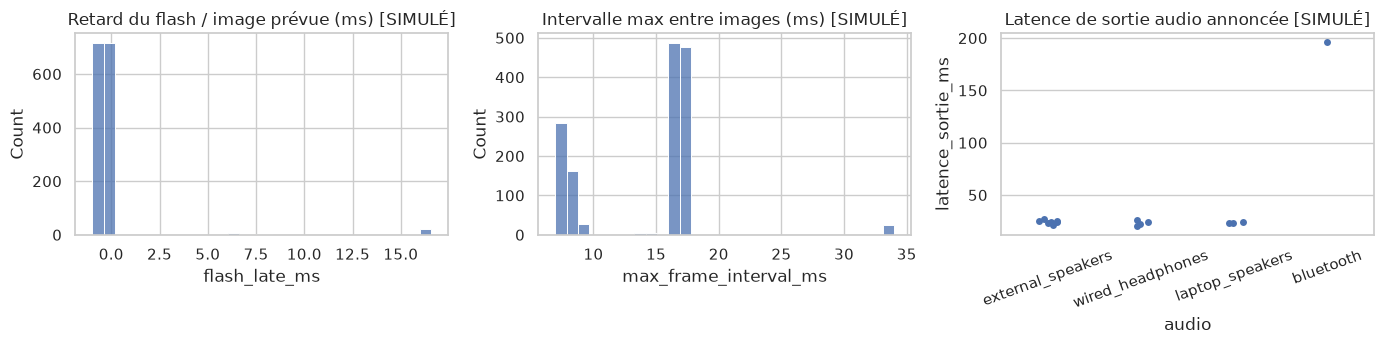

In [18]:
diag = main.groupby("participant_id").agg(
    audio=("audio_device", "first"), refresh_hz=("refresh_hz", "median"),
    images_perdues=("n_dropped_frames", "sum"), retard_flash_moy_ms=("flash_late_ms", "mean"),
    duree_flash_ms=("flash_dur_ms_actual", "median"), soa_flash_ms=("flash_soa_ms_actual", "median"),
    avance_son_min_ms=("audio_lead_ms", "min"), derive_horloges_max_ms=("audio_clock_drift_ms", lambda s: s.abs().max()),
    latence_sortie_ms=("output_latency_ms", "median"), essais_exclus=("exclude_trial", "mean"),
    mapping=("audio_mapping", "first"))
display(diag.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(main.flash_late_ms.dropna(), bins=30, ax=axes[0]); axes[0].set_title("Retard du flash / image prévue (ms)" + TAG)
sns.histplot(main.max_frame_interval_ms.dropna(), bins=30, ax=axes[1]); axes[1].set_title("Intervalle max entre images (ms)" + TAG)
sns.stripplot(data=sessions.reset_index(), x="audio", y="latence_sortie_ms", ax=axes[2])
axes[2].set_title("Latence de sortie audio annoncée" + TAG); axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG_DIR / f"fig3_timing{SUFFIX}.png", dpi=150); plt.show()

## 8. Conclusion

*(À rédiger une fois les vraies données collectées : ne rien conclure à partir des données simulées.)*

Points à rapporter :
1. Nombre de participants testés, exclus (et pourquoi), analysés ;
2. **H1** : t(ddl) = …, p = …, d = … — l'illusion de fission est-elle répliquée en ligne ? Ampleur comparée à l'article (≈ 1,9 flash perçu pour 1 flash + 2 bips chez Shams et al., 2000) ;
3. **H2** : fusion (Shams et al. : pas d'effet de fusion ; d'autres études en trouvent un, plus faible) ;
4. **H3** : interaction flashs × bips de l'ANOVA ;
5. **H4** : décroissance avec l'écart entre les bips (Shams et al. : illusion jusqu'à ≈ 100 ms), fenêtre TBW50 du groupe et dispersion individuelle ;
6. Détection du signal : l'illusion modifie-t-elle la sensibilité d′ (effet perceptif) ou seulement le critère (biais) ?
7. Limites : timing du navigateur (son/image non mesurés physiquement), matériel hétérogène, petit échantillon, peu d'essais par condition.